Exactitud: ¿Qué tan cerca está una medición del valor verdadero?
Precisión: ¿Qué tan consistentes son las mediciones entre sí?


Enter the function in terms of x (e.g., x**2 - 4): sin(x) - x
Enter the lower bound of the interval a: -1
Enter the upper bound of the interval b: 1

Iteration results:
Iter |    a    |    b    |    c    |  f(c)  |  |c-a|  | |c-a|/c 
   1 | -1.0000 |  1.0000 |  0.0000 |  0.0000 | 1.0000e+00 |     inf

Root found: 0.000000


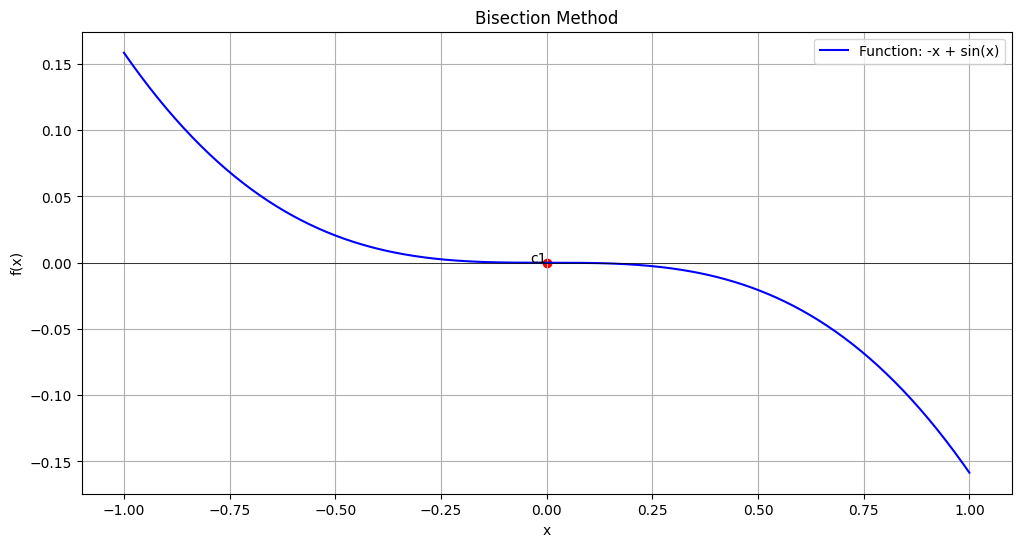

In [ ]:
#METODO DE LA BISECCION
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

def bisection_method(func, a, b, tol=1e-6, max_iter=100):
    x = sp.symbols('x')
    f = sp.lambdify(x, func, 'numpy')

    iter_data = []

    if f(a) * f(b) > 0:
        raise ValueError("The function must have different signs at the endpoints a and b.")

    for i in range(max_iter):
        c = (a + b) / 2
        f_c = f(c)
        abs_c_minus_a = abs(c - a)
        rel_error = abs_c_minus_a / abs(c) if c != 0 else float('inf')

        iter_data.append([i + 1, a, b, c, f_c, abs_c_minus_a, rel_error])

        if abs(f_c) < tol or abs_c_minus_a < tol:
            break

        if f(a) * f_c < 0:
            b = c
        else:
            a = c

    return np.array(iter_data), c

def plot_results(func, a, b, iter_data):
    x_vals = np.linspace(a, b, 400)
    x = sp.symbols('x')
    f = sp.lambdify(x, func, 'numpy')

    plt.figure(figsize=(12, 6))
    plt.plot(x_vals, f(x_vals), label=f'Function: {func}', color='blue')
    plt.axhline(0, color='black', linewidth=0.5)

    for i, data in enumerate(iter_data):
        plt.scatter(data[3], 0, color='red')
        plt.text(data[3], 0, f'c{i+1}', horizontalalignment='right')

    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.title('Bisection Method')
    plt.legend()
    plt.grid(True)
    plt.show()

def main():
    expr = input("Enter the function in terms of x (e.g., x**2 - 4): ")
    a = float(input("Enter the lower bound of the interval a: "))
    b = float(input("Enter the upper bound of the interval b: "))

    func = sp.sympify(expr)

    iter_data, root = bisection_method(func, a, b)

    print("\nIteration results:")
    print("Iter |    a    |    b    |    c    |  f(c)  |  |c-a|  | |c-a|/c ")
    for row in iter_data:
        print(f"{int(row[0]):4d} | {row[1]:7.4f} | {row[2]:7.4f} | {row[3]:7.4f} | {row[4]:7.4f} | {row[5]:7.4e} | {row[6]:7.4e}")

    print(f"\nRoot found: {root:.6f}")

    plot_results(func, a, b, iter_data)

main()





In [ ]:
#METODO DEL BISECCION PERO PIDE LA TOLERANCIA

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

def biseccion(funcion, a, b, tol=1e-6, max_iter=100):
    # Definir la función simbólica y convertirla en función numérica
    x = sp.symbols('x')
    f_simbolica = sp.sympify(funcion)
    f = sp.lambdify(x, f_simbolica, 'numpy')

    # Validar que f(a) * f(b) < 0
    if f(a) * f(b) > 0:
        print("El intervalo no es válido. f(a) y f(b) deben tener signos opuestos.")
        return

    # Inicializar variables
    tabla = []
    iteracion = 0
    c = (a + b) / 2.0
    error_abs = abs(c - a)
    error_relativo = abs(error_abs / c) if c != 0 else ''

    # Iterar hasta que se cumpla la tolerancia o se alcance el máximo de iteraciones
    while error_abs > tol and iteracion < max_iter:
        iteracion += 1
        c = (a + b) / 2.0
        f_c = f(c)
        error_abs = abs(c - a)
        error_relativo = abs(error_abs / c) if c != 0 else ''

        # Guardar resultados de la iteración
        tabla.append([iteracion, a, b, c, f_c, error_abs, error_relativo])

        # Actualizar los valores de a y b según el signo de f(c)
        if f(a) * f_c < 0:
            b = c
        else:
            a = c

    # Mostrar tabla de resultados
    print("Iteración | a | b | c | f(c) | |c - a| | |(c - a) / c|")
    print("----------------------------------------------------------")
    for fila in tabla:
        print(f"{fila[0]:^9} | {fila[1]:^5.5f} | {fila[2]:^5.5f} | {fila[3]:^5.5f} | {fila[4]:^7.5f} | {fila[5]:^7.5f} | {fila[6] if fila[6] != '' else '':^7}")

    # Graficar la función y el punto medio en cada iteración
    x_vals = np.linspace(a, b, 400)
    y_vals = f(x_vals)

    plt.plot(x_vals, y_vals, label='f(x)')
    plt.axhline(0, color='black', linewidth=0.5)

    for i, fila in enumerate(tabla):
        plt.plot(fila[3], f(fila[3]), 'ro')
        plt.annotate(f'Iter {fila[0]}', (fila[3], f(fila[3])), textcoords="offset points", xytext=(0,10), ha='center')

    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.title('Método de Bisección')
    plt.legend()
    plt.grid(True)
    plt.show()

# Ejemplo de uso
funcion = input("Ingresa la función (usa 'x' como variable): ")
a = float(input("Ingresa el límite inferior del intervalo (a): "))
b = float(input("Ingresa el límite superior del intervalo (b): "))
tol = float(input("Ingresa la tolerancia: "))
max_iter = int(input("Ingresa el número máximo de iteraciones: "))

biseccion(funcion, a, b, tol, max_iter)


Ingresa la función (usa 'x' como variable): exp(x) - x - ln(x)
Ingresa el límite inferior del intervalo (a): 0.6
Ingresa el límite superior del intervalo (b): 0.8
Ingresa la tolerancia: 0.001
Ingresa el número máximo de iteraciones: 15
El intervalo no es válido. f(a) y f(b) deben tener signos opuestos.


In [ ]:
#METODO NEWTON RAPHSON  f(x_0+h)=f(x_0)+hf`(x_0)-------h=f(x_0)/f`(x_0)----------------X_n=X_n-1-f(x_n-1)/f`(x_)
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

def newton_raphson_method(func, initial_guess, tol=1e-6, max_iter=100):
    x = sp.symbols('x')
    f = sp.lambdify(x, func, 'numpy')
    f_prime = sp.lambdify(x, sp.diff(func, x), 'numpy')

    iter_data = []
    c = initial_guess
    epsilon = 1e-10  # Pequeño valor para evitar división por cero

    for i in range(max_iter):
        f_c = f(c)
        f_prime_c = f_prime(c)

        if abs(f_prime_c) < epsilon:
            raise ValueError("The derivative is too close to zero. Newton-Raphson method fails.")

        next_c = c - f_c / f_prime_c
        abs_c_minus_a = abs(next_c - c)
        rel_error = abs_c_minus_a / abs(next_c) if next_c != 0 else float('inf')

        iter_data.append([i + 1, c, f_c, f_prime_c, next_c, abs_c_minus_a, rel_error])

        if abs(f_c) < tol or abs_c_minus_a < tol:
            break

        c = next_c

    return np.array(iter_data), c

def plot_newton_raphson(func, iter_data):
    x_vals = np.linspace(min(iter_data[:, 1])-1, max(iter_data[:, 1])+1, 400)
    x = sp.symbols('x')
    f = sp.lambdify(x, func, 'numpy')

    plt.figure(figsize=(12, 6))
    plt.plot(x_vals, f(x_vals), label=f'Function: {func}', color='blue')
    plt.axhline(0, color='black', linewidth=0.5)

    for i, data in enumerate(iter_data):
        plt.scatter(data[1], 0, color='red')
        plt.text(data[1], 0, f'p{i+1}', horizontalalignment='right')

    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.title('Newton-Raphson Method')
    plt.legend()
    plt.grid(True)
    plt.show()

def main():
    expr = input("Enter the function f(x) in terms of x (e.g., x**2 - 4): ")
    initial_guess = float(input("Enter the initial guess: "))

    func = sp.sympify(expr)

    try:
        iter_data, root = newton_raphson_method(func, initial_guess)
        print("\nIteration results:")
        print("Iter |    c    |  f(c)  |  f'(c)  |  next_c  |  |c - a|  | |c - a|/c ")
        for row in iter_data:
            print(f"{int(row[0]):4d} | {row[1]:7.4f} | {row[2]:7.4f} | {row[3]:7.4f} | {row[4]:7.4f} | {row[5]:7.4e} | {row[6]:7.4e}")

        print(f"\nRoot found: {root:.6f}")

        plot_newton_raphson(func, iter_data)
    except ValueError as e:
        print(f"Error: {e}")

main()




Enter the function f(x) in terms of x (e.g., x**2 - 4): exp(x) - x
Enter the initial guess: 1
Error: The derivative is too close to zero. Newton-Raphson method fails.


Ingrese la función (en términos de x): 2**-x
Ingrese el extremo inferior del intervalo a: 1
Ingrese el extremo superior del intervalo b: 3.1
Ingrese la tolerancia (default 1e-6): 0.001
Iteración  a               b               c               abs(c - a)      abs(c - a) / c 
1          1.0             3.1             3.7388621973501777 2.7388621973501777 0.7325389524361919
2          3.7388621973501777 3.1             4.885624821855143 1.1467626245049654 0.2347217943087007
3          4.885624821855143 3.1             5.615142838332847 0.7295180164777042 0.12991976116751827
4          5.615142838332847 3.1             6.148402706275895 0.5332598679430474 0.08673144773011207
5          6.148402706275895 3.1             6.5675449634114 0.4191422571355057 0.06382023411649233
6          6.5675449634114 3.1             6.91216161536988 0.34461665195847946 0.04985656747263982
7          6.91216161536988 3.1             7.204354669480384 0.29219305411050467 0.04055783862894956
8          7.204

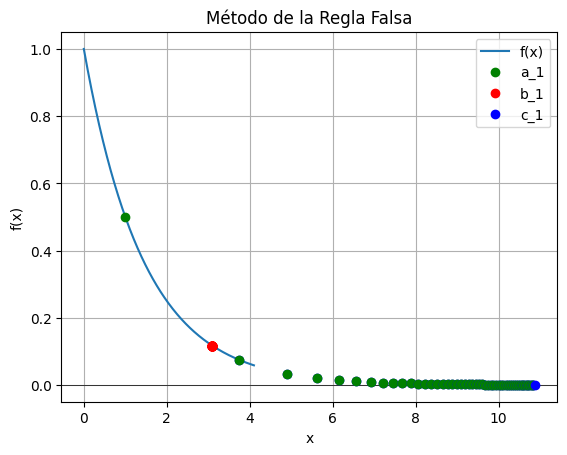

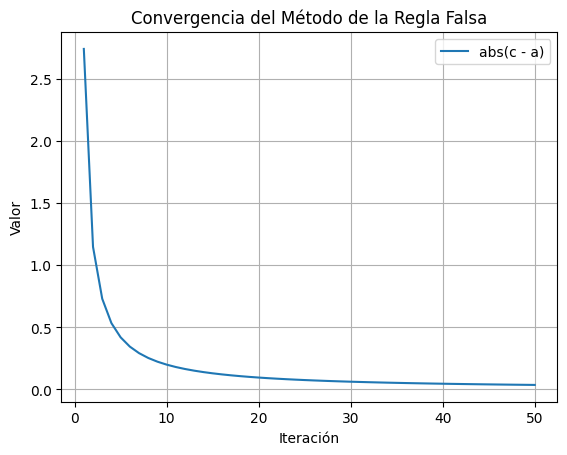

In [ ]:
#EL METODO DE LA REGLA FALSA c=X_b-f(x_b)(x_a-x_b)/(f(x_a)-f(x_b))  unque ambos métodos utilizan aproximaciones lineales para iterar hacia una solución, el método de la regla falsa usa una línea secante (entre dos puntos), mientras que el método de Newton utiliza la tangente en un punto. Por esta razón, se dice que el método de la regla falsa es un método similar al de Newton, pero sin el uso de derivadas.
import numpy as np
import matplotlib.pyplot as plt

def regla_falsa(f, a, b, tol=1e-6, max_iter=50):
    # Función f como lambda
    f = eval("lambda x: " + f)

    # Listas para almacenar resultados
    iters = []
    a_vals = []
    b_vals = []
    c_vals = []
    abs_vals = []
    abs_div_c_vals = []

    iter_count = 0
    while True:
        iter_count += 1

        # Calcular el valor de c usando la fórmula de la regla falsa
        fa = f(a)
        fb = f(b)

        # Evitar división por cero
        if fa == fb:
            print("Error: f(a) y f(b) son iguales, lo que causa una división por cero.")
            break

        c = b - (fb * (a - b)) / (fa - fb)
        fc = f(c)

        # Almacenar resultados
        iters.append(iter_count)
        a_vals.append(a)
        b_vals.append(b)
        c_vals.append(c)
        abs_c_a = abs(c - a)
        abs_vals.append(abs_c_a)

        if c != 0:
            abs_div_c_vals.append(abs_c_a / abs(c))
        else:
            abs_div_c_vals.append('')

        # Verificar la tolerancia o si se ha alcanzado el máximo de iteraciones
        if abs_c_a < tol or iter_count >= max_iter:
            break

        # Decidir el siguiente intervalo
        if fa * fc < 0:
            b = c
        else:
            a = c

    # Crear tabla de resultados
    print("{:<10} {:<15} {:<15} {:<15} {:<15} {:<15}".format(
        "Iteración", "a", "b", "c", "abs(c - a)", "abs(c - a) / c"))
    for i in range(len(iters)):
        print("{:<10} {:<15} {:<15} {:<15} {:<15} {:<15}".format(
            iters[i], a_vals[i], b_vals[i], c_vals[i], abs_vals[i], abs_div_c_vals[i]))

    # Graficar la función y los puntos de iteración
    x = np.linspace(min(a_vals) - 1, max(b_vals) + 1, 400)
    y = f(x)

    plt.plot(x, y, label='f(x)')
    plt.axhline(0, color='black', linewidth=0.5)

    # Graficar puntos a, b y c
    for i in range(len(a_vals)):
        plt.plot(a_vals[i], f(a_vals[i]), 'go', label=f'a_{i+1}' if i == 0 else "")
        plt.plot(b_vals[i], f(b_vals[i]), 'ro', label=f'b_{i+1}' if i == 0 else "")
        plt.plot(c_vals[i], f(c_vals[i]), 'bo', label=f'c_{i+1}' if i == 0 else "")

    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.title('Método de la Regla Falsa')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Graficar los resultados de las iteraciones
    plt.plot(iters, abs_vals, label='abs(c - a)')
    plt.xlabel('Iteración')
    plt.ylabel('Valor')
    plt.title('Convergencia del Método de la Regla Falsa')
    plt.legend()
    plt.grid(True)
    plt.show()

# Ejemplo de uso:
f = input("Ingrese la función (en términos de x): ")
a = float(input("Ingrese el extremo inferior del intervalo a: "))
b = float(input("Ingrese el extremo superior del intervalo b: "))
tol = float(input("Ingrese la tolerancia (default 1e-6): ") or 1e-6)

regla_falsa(f, a, b, tol)



Introduce la función en términos de x (por ejemplo, 'x**3 - 6*x**2 + 9*x + 15'): exp(x) - x- ln(x)
Introduce el rango de x (por ejemplo, '-2 5'): 0 5


<lambdifygenerated-11>:2: RuntimeWarning: divide by zero encountered in log
  return -x + exp(x) - log(x)


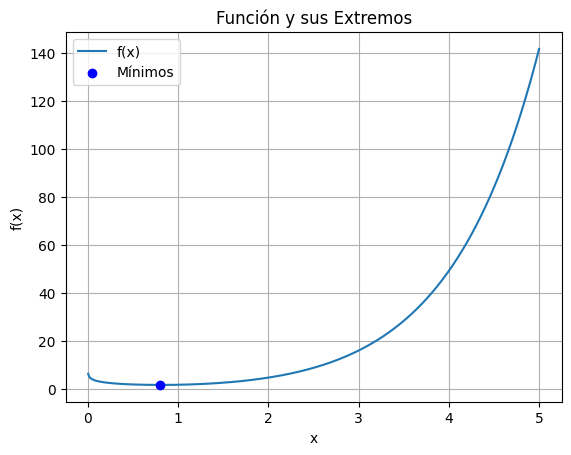

In [ ]:
#PARA ENCONTRAR MINIMOS
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

def get_function_from_input():
    func_str = input("Introduce la función en términos de x (por ejemplo, 'x**3 - 6*x**2 + 9*x + 15'): ")
    x = sp.Symbol('x')
    try:
        func = sp.sympify(func_str)
        return sp.lambdify(x, func, 'numpy')
    except Exception as e:
        print(f"Error al interpretar la función: {e}")
        return None

def find_extrema(f, x_range):
    x_vals = np.linspace(x_range[0], x_range[1], 1000)
    y_vals = f(x_vals)

    maxima = []
    minima = []

    for i in range(1, len(x_vals) - 1):
        if y_vals[i - 1] < y_vals[i] > y_vals[i + 1]:
            maxima.append((x_vals[i], y_vals[i]))
        elif y_vals[i - 1] > y_vals[i] < y_vals[i + 1]:
            minima.append((x_vals[i], y_vals[i]))

    return maxima, minima

def plot_function_with_extrema(f, x_range):
    x_vals = np.linspace(x_range[0], x_range[1], 1000)
    y_vals = f(x_vals)

    maxima, minima = find_extrema(f, x_range)

    plt.plot(x_vals, y_vals, label='f(x)')

    if maxima:
        max_x, max_y = zip(*maxima)
        plt.scatter(max_x, max_y, color='red', label='Máximos', zorder=5)

    if minima:
        min_x, min_y = zip(*minima)
        plt.scatter(min_x, min_y, color='blue', label='Mínimos', zorder=5)

    plt.title('Función y sus Extremos')
    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.legend()
    plt.grid(True)
    plt.show()

def main():
    # Solicita la función al usuario
    f = get_function_from_input()

    if f is None:
        return

    # Define el rango de valores de x para graficar
    x_range = tuple(map(float, input("Introduce el rango de x (por ejemplo, '-2 5'): ").split()))

    # Llama a la función para graficar
    plot_function_with_extrema(f, x_range)

if __name__ == "__main__":
    main()


Ingrese la función g(x) (por ejemplo, np.cos(x)): np.cos(x)
Ingrese el punto inicial: 1
Ingrese la tolerancia: 0.001
Iteración	 x_n		 |c - a|	 |c - a|/c
1		 0.540302	 0.459698	 0.850816
2		 -0.416147	 0.317251	 0.369949
3		 -0.989992	 0.203263	 0.310663
4		 -0.653644	 0.139191	 0.175418
5		 0.283662	 0.092112	 0.131331
6		 0.960170	 0.062591	 0.081930
7		 0.753902	 0.041857	 0.057966
8		 -0.145500	 0.028315	 0.037733
9		 -0.911130	 0.019014	 0.025996
10		 -0.839072	 0.012833	 0.017244
11		 0.004426	 0.008633	 0.011735
12		 0.843854	 0.005820	 0.007850
13		 0.907447	 0.003918	 0.005313
14		 0.136737	 0.002640	 0.003567
15		 -0.759688	 0.001778	 0.002408
16		 -0.957659	 0.001198	 0.001620


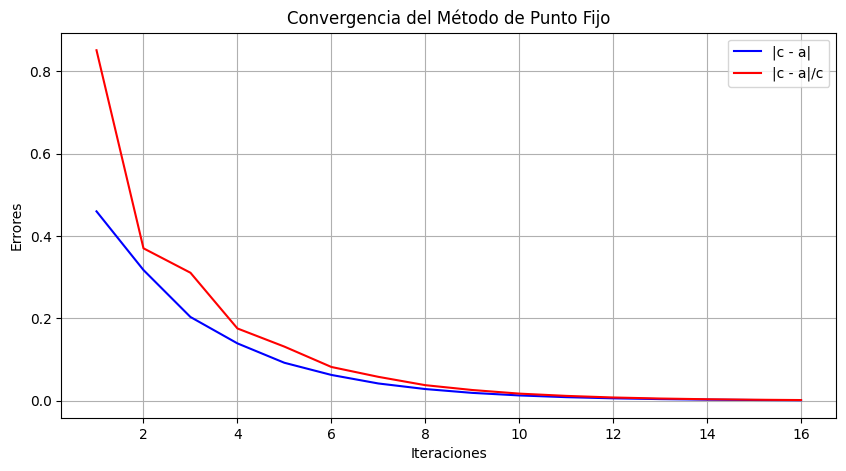

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def punto_fijo(g, x0, tol):
    # Variables para almacenar resultados
    iteraciones = []
    errores_absolutos = []
    errores_relativos = []

    # Primera iteración
    x_anterior = x0
    x_actual = g(x_anterior)
    iteracion = 1

    while abs(x_actual - x_anterior) > tol:
        # Guardar datos para la tabla
        iteraciones.append(iteracion)
        error_absoluto = abs(x_actual - x_anterior)
        errores_absolutos.append(error_absoluto)

        if x_actual != 0:
            error_relativo = error_absoluto / abs(x_actual)
            errores_relativos.append(error_relativo)
        else:
            errores_relativos.append(None)  # Dejar celda vacía si c es cero

        # Actualizar valores para la siguiente iteración
        x_anterior = x_actual
        x_actual = g(x_anterior)
        iteracion += 1

    # Mostrar la tabla de iteraciones
    print("Iteración\t x_n\t\t |c - a|\t |c - a|/c")
    for i in range(len(iteraciones)):
        iteracion = iteraciones[i]
        x_n = g(iteraciones[i])
        error_abs = errores_absolutos[i]
        error_rel = errores_relativos[i]
        if error_rel is not None:
            print(f"{iteracion}\t\t {x_n:.6f}\t {error_abs:.6f}\t {error_rel:.6f}")
        else:
            print(f"{iteracion}\t\t {x_n:.6f}\t {error_abs:.6f}\t ")

    # Gráfica de los resultados
    plt.figure(figsize=(10, 5))
    plt.plot(iteraciones, errores_absolutos, 'b-', label='|c - a|')
    plt.plot(iteraciones, errores_relativos, 'r-', label='|c - a|/c')
    plt.xlabel('Iteraciones')
    plt.ylabel('Errores')
    plt.title('Convergencia del Método de Punto Fijo')
    plt.legend()
    plt.grid(True)
    plt.show()

# Ejemplo de uso
# Solicitar al usuario la función, el punto inicial y la tolerancia
funcion = input("Ingrese la función g(x) (por ejemplo, np.cos(x)): ")
g = eval(f"lambda x: {funcion}")
x0 = float(input("Ingrese el punto inicial: "))
tol = float(input("Ingrese la tolerancia: "))

punto_fijo(g, x0, tol)


a razón por la cual la función
𝑓
(
𝑥
)
=
ℎ
(
𝑥
)
−
𝑔
(
𝑥
)
f(x)=h(x)−g(x) se convierte en cero en los puntos de intersección es porque, en esos puntos,
ℎ
(
𝑥
)
h(x) y
𝑔
(
𝑥
)
g(x) tienen el mismo valor, y su diferencia es cero. Esto nos dice que en esos puntos, las funciones
ℎ
(
𝑥
)
h(x) y
𝑔
(
𝑥
)
g(x) se intersecan. No es que la suma de
ℎ
(
𝑥
)
h(x) y
𝑔
(
𝑥
)
g(x) dé cero, sino que su diferencia es lo que da cero, señalando la intersección.